In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import shutil

# Copies the file from temporary storage into your permanent Google Drive - Gemini
shutil.copy("/content/best_pneumonia_resnet18.pth", "/content/drive/MyDrive/best_pneumonia_resnet18.pth")


'/content/drive/MyDrive/best_pneumonia_resnet18.pth'

In [ ]:
pip install medmnist

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [medmnist]


In [ ]:
from medmnist import PneumoniaMNIST

In [ ]:
import numpy as np

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models
from torchvision.models import resnet18, ResNet18_Weights
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
# To evaluate the data form the medimnist dataset
from medmnist import INFO, Evaluator

In [ ]:
# Load the pre-trained ResNet-18 model
model = models.resnet18(weights=ResNet18_Weights.DEFAULT) # since pretrained=True is no longer used in modern code i think
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu') # . If your model is on the GPU while your data remains on the CPU, PyTorch will throw a runtime error.

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 84.6MB/s]


In [ ]:
# Define preprocessing trandforms
data_transform = transforms.Compose([
    #transforms.Resize((224, 224)), too heavy
    transforms.Grayscale(num_output_channels=3), # Converts images to grayscale
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)) # Mean and std
])

# Download and load splits
train_dataset = PneumoniaMNIST(split="train", transform=data_transform, download=True)
val_dataset = PneumoniaMNIST(split="val", transform=data_transform, download=True)
test_dataset = PneumoniaMNIST(split="test", transform=data_transform, download=True)

# Wrap in a PyTorch Dataloader
train_loader = DataLoader(dataset=train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(dataset=val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(dataset=test_dataset, batch_size=32, shuffle=False)

100%|██████████| 4.17M/4.17M [00:06<00:00, 682kB/s]


In [ ]:
# Replace the final layer (originally 512 -> 1000) with (512 -> 1) for binary classification
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 1) # Changed form 2 to 1 as the CrossEntropy changed to Binary Cross Entropy
#model = model.to(device) already mentioned later in the training func

Exploring the dataset

In [ ]:
#print the number of images in each dataset split
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

Training images: 4708
Validation images: 524
Testing images: 624


In [ ]:
import numpy as np

# loop through each dataset split to examine its class distribution
for name, dataset in [
    ("Training", train_dataset),
    ("Validation", val_dataset),
    ("Testing", test_dataset)
]:
# count how many images belong to each label
    labels, counts = np.unique(dataset.labels, return_counts=True)
    print(name)
    for label, count in zip(labels, counts):
        print(f"Label {label}: {count} images") # 0 - Healthy, 1 - Pneumonia
    print()

Training
Label 0: 1214 images
Label 1: 3494 images

Validation
Label 0: 135 images
Label 1: 389 images

Testing
Label 0: 234 images
Label 1: 390 images



In [ ]:
# check the dimensions, data type and pixel intensity range of the training images
print("Image shape:", train_dataset.imgs.shape)
print("Image data type:", train_dataset.imgs.dtype)
print("Minimum pixel value:", train_dataset.imgs.min())
print("Maximum pixel value:", train_dataset.imgs.max())
print("Label shape:", train_dataset.labels.shape)

Image shape: (4708, 28, 28)
Image data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255
Label shape: (4708, 1)


In [ ]:
# Count images where every pixel has a value of 0
blank_images = np.sum(np.all(train_dataset.imgs == 0, axis=(1, 2)))

# Display the number of completely blank images
print("Completely blank images:", blank_images)

Completely blank images: 0


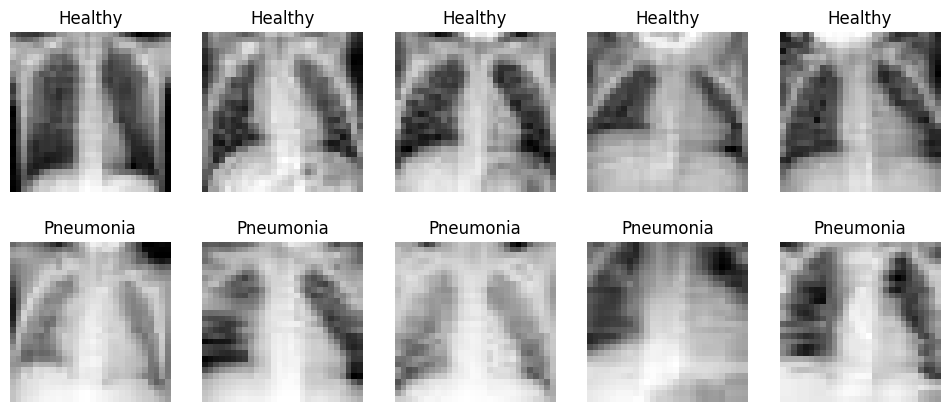

In [ ]:
# Import matplotlib for displaying images
import matplotlib.pyplot as plt

# Create a grid with 2 rows and 5 columns
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

# Display 5 images from each class
for label, row in zip([0, 1], [0, 1]):
    indices = np.where(train_dataset.labels.flatten() == label)[0][:5]

    for col, idx in enumerate(indices):
      # Display the image in grayscale
        axes[row, col].imshow(train_dataset.imgs[idx], cmap="gray")
        # Add the correct class name as the title
        axes[row, col].set_title(
            "Healthy" if label == 0 else "Pneumonia"
        )
        # Hide the axis numbers
        axes[row, col].axis("off")

plt.show()

In [ ]:
# Count any missing (NaN) pixel values
print("NaN values:", np.isnan(train_dataset.imgs).sum())

# Count any infinite pixel values
print("Infinite values:", np.isinf(train_dataset.imgs).sum())

# Count the number of different pixel intensity values
print("Unique pixel values:", len(np.unique(train_dataset.imgs)))

NaN values: 0
Infinite values: 0
Unique pixel values: 256


In [ ]:
# Calculate the average pixel brightness of each training image
mean_brightness = np.mean(train_dataset.imgs, axis=(1, 2))

# Find the darkest image's average brightness
print("Darkest image:", mean_brightness.min())

# Find the brightest image's average brightness
print("Brightest image:", mean_brightness.max())

# Calculate the average brightness across all training images
print("Average brightness:", mean_brightness.mean())

Darkest image: 70.56760204081633
Brightest image: 225.5012755102041
Average brightness: 145.83999824441247


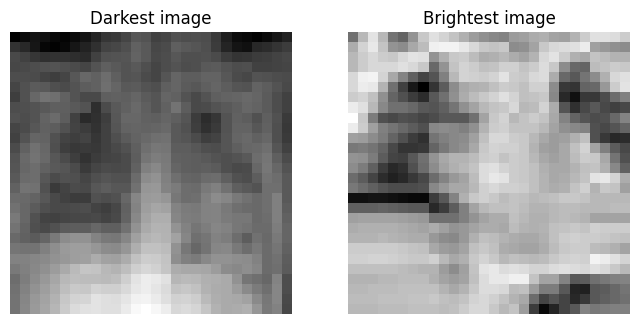

In [ ]:
# Find the index of the darkest image
darkest_idx = np.argmin(mean_brightness)

# Find the index of the brightest image
brightest_idx = np.argmax(mean_brightness)

# Create a figure with two images side by side
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

# Display the darkest image
axes[0].imshow(train_dataset.imgs[darkest_idx], cmap="gray")
axes[0].set_title("Darkest image")

# Display the brightest image
axes[1].imshow(train_dataset.imgs[brightest_idx], cmap="gray")
axes[1].set_title("Brightest image")

#Hide the axis number
for ax in axes:
    ax.axis("off")

#Display the image
plt.show()

In [ ]:

# Find images where the maximum and minimum pixel values are equal
uniform_images = np.sum(
    np.max(train_dataset.imgs, axis=(1, 2)) ==
    np.min(train_dataset.imgs, axis=(1, 2))
)

# Display the number of completely uniform images
print("Completely uniform images:", uniform_images)

Completely uniform images: 0


In [ ]:
# Calculate the standard deviation of pixel values in each image
image_stds = np.std(train_dataset.imgs, axis=(1, 2))

# Count images with no pixel variation
print("Images with zero variation:", np.sum(image_stds == 0))

# Find the lowest standard deviation across all images
print("Lowest image variation:", image_stds.min())

Images with zero variation: 0
Lowest image variation: 6.3159782799383555


In [ ]:
# Import hashlib to create a unique hash for each image
import hashlib

# Generate a hash for every training image
hashes = [
    hashlib.md5(img.tobytes()).hexdigest()
    for img in train_dataset.imgs
]

# Count how many images are duplicates
print("Duplicate images:", len(hashes) - len(set(hashes)))

Duplicate images: 18


In [ ]:
# Create a function to generate hashes for all images in a dataset
def get_hashes(dataset):
    return {
        hashlib.md5(img.tobytes()).hexdigest()
        for img in dataset.imgs
    }

# Generate hashes for each dataset split
train_hashes = get_hashes(train_dataset)
val_hashes = get_hashes(val_dataset)
test_hashes = get_hashes(test_dataset)

# Count identical images shared between the splits
print("Train-validation overlap:", len(train_hashes & val_hashes))
print("Train-test overlap:", len(train_hashes & test_hashes))
print("Validation-test overlap:", len(val_hashes & test_hashes))

Train-validation overlap: 8
Train-test overlap: 0
Validation-test overlap: 0


In [ ]:
# Create a function that links each image hash to its label
def get_image_labels(dataset):
    return {
        hashlib.md5(img.tobytes()).hexdigest(): int(label[0])
        for img, label in zip(dataset.imgs, dataset.labels)
    }

# Get image hashes and labels for training and validation
train_dict = get_image_labels(train_dataset)
val_dict = get_image_labels(val_dataset)

# Find images that appear in both splits
overlap = set(train_dict) & set(val_dict)

# Display the labels of matching images
for h in overlap:
    print("Train label:", train_dict[h], "| Validation label:", val_dict[h])

Train label: 1 | Validation label: 1
Train label: 1 | Validation label: 1
Train label: 1 | Validation label: 1
Train label: 1 | Validation label: 1
Train label: 1 | Validation label: 1
Train label: 1 | Validation label: 1
Train label: 1 | Validation label: 1
Train label: 1 | Validation label: 1


In [ ]:
# Import defaultdict to group labels belonging to the same image
from collections import defaultdict

# Create a dictionary to store all labels for each image
image_labels = defaultdict(set)

# Group images by their hash and record their labels
for img, label in zip(train_dataset.imgs, train_dataset.labels):
    h = hashlib.md5(img.tobytes()).hexdigest()
    image_labels[h].add(int(label[0]))

# Count images that have more than one different label
conflicts = sum(len(labels) > 1 for labels in image_labels.values())

# Display the number of conflicting images
print("Images with conflicting labels:", conflicts)

Images with conflicting labels: 0


In [ ]:
train_indices = {
    hashlib.md5(img.tobytes()).hexdigest(): i
    for i, img in enumerate(train_dataset.imgs)
}

val_indices = {
    hashlib.md5(img.tobytes()).hexdigest(): i
    for i, img in enumerate(val_dataset.imgs)
}

for h in overlap:
    print(
        "Training index:", train_indices[h],
        "| Validation index:", val_indices[h]
    )

Training index: 2041 | Validation index: 61
Training index: 1834 | Validation index: 473
Training index: 4036 | Validation index: 244
Training index: 662 | Validation index: 236
Training index: 3130 | Validation index: 302
Training index: 3170 | Validation index: 172
Training index: 3874 | Validation index: 253
Training index: 4193 | Validation index: 105


In [ ]:
from sklearn.neighbors import NearestNeighbors

# Flatten the images into 1D arrays
train_images = train_dataset.imgs.reshape(len(train_dataset), -1).astype(np.float32)
val_images = val_dataset.imgs.reshape(len(val_dataset), -1).astype(np.float32)

# Find the closest training image for each validation image
neighbours = NearestNeighbors(n_neighbors=1, metric="euclidean")
neighbours.fit(train_images)

distances, indices = neighbours.kneighbors(val_images)

# Exclude exact duplicates (distance = 0)
nonzero = distances[:, 0] > 0

# Find the 10 closest non-identical image pairs
closest = np.argsort(np.where(nonzero, distances[:, 0], np.inf))[:10]

for i in closest:
    print(
        "Validation index:", i,
        "| Closest training index:", indices[i][0],
        "| Pixel distance:", round(distances[i][0], 2)
    )

Validation index: 194 | Closest training index: 3327 | Pixel distance: 250.06
Validation index: 301 | Closest training index: 4219 | Pixel distance: 255.94
Validation index: 279 | Closest training index: 1733 | Pixel distance: 260.33
Validation index: 208 | Closest training index: 3286 | Pixel distance: 286.76
Validation index: 153 | Closest training index: 839 | Pixel distance: 298.21
Validation index: 169 | Closest training index: 3793 | Pixel distance: 299.38
Validation index: 520 | Closest training index: 4520 | Pixel distance: 321.74
Validation index: 294 | Closest training index: 2775 | Pixel distance: 336.0
Validation index: 377 | Closest training index: 635 | Pixel distance: 340.88
Validation index: 495 | Closest training index: 3796 | Pixel distance: 347.53


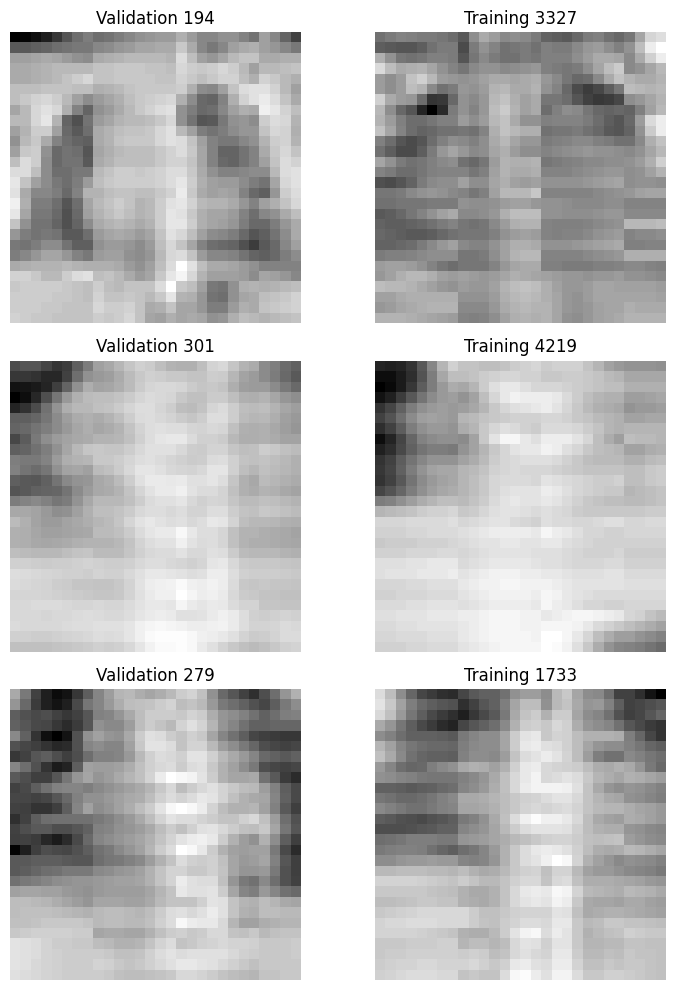

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(8, 10))

for row, i in enumerate(closest[:3]):
    val_idx = i
    train_idx = indices[i][0]

    axes[row, 0].imshow(val_dataset.imgs[val_idx], cmap="gray")
    axes[row, 0].set_title(f"Validation {val_idx}")

    axes[row, 1].imshow(train_dataset.imgs[train_idx], cmap="gray")
    axes[row, 1].set_title(f"Training {train_idx}")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Printing the data and its labels from PneumoniaMNIST
data_flag = 'pneumoniamnist'
download = True

NUM_EPOCHS = 3
BATCH_SIZE = 128
lr = 0.001

info = INFO[data_flag]
task = info['task']
n_channels = info['n_channels']
n_classes = len(info['label'])

info

{'python_class': 'PneumoniaMNIST',
 'description': 'The PneumoniaMNIST is based on a prior dataset of 5,856 pediatric chest X-Ray images. The task is binary-class classification of pneumonia against normal. We split the source training set with a ratio of 9:1 into training and validation set and use its source validation set as the test set. The source images are gray-scale, and their sizes are (384−2,916)×(127−2,713). We center-crop the images and resize them into 1×28×28.',
 'url': 'https://zenodo.org/records/10519652/files/pneumoniamnist.npz?download=1',
 'MD5': '28209eda62fecd6e6a2d98b1501bb15f',
 'url_64': 'https://zenodo.org/records/10519652/files/pneumoniamnist_64.npz?download=1',
 'MD5_64': '8f4eceb4ccffa70c672198ea285246c6',
 'url_128': 'https://zenodo.org/records/10519652/files/pneumoniamnist_128.npz?download=1',
 'MD5_128': '05b46931834c231683c68f40c47b2971',
 'url_224': 'https://zenodo.org/records/10519652/files/pneumoniamnist_224.npz?download=1',
 'MD5_224': 'd6a3c71de1b94

Back to the model

In [ ]:
# Loss function and optimization
criterion = torch.nn.BCEWithLogitsLoss() # measures the difference between a model's predicted probability distribution and the true target labels in classification tasks - qunatifies error
#Changed the learnign rate from 0.001 to 0.00001 as not to destroy the model's pre-trained weights
optimizer = torch.optim.SGD(model.fc.parameters(), lr=0.  , momentum=0.9) #initializes a Stochastic Gradient Descent (SGD) optimizer in PyTorch to update only the final fully connected (fc) layer of a neural network

Optimization of Hyperparameter (like Learning Rate)

In [ ]:
#train(model, train_loader, val_loader, criterion, optimizer, num_epochs=5)

NameError: name 'train' is not defined

Function to Train a Model

In [ ]:
def train(model, train_loader, val_loader, criterion, optimizer, num_epochs):
  best_val_loss = float('inf')
  for epoch in range(num_epochs):
    model.train() # Sets the model to trianing mode: notifying the model that it is now in learnign model

    # Initializes running loss and correct predictions count for training
    running_loss = 0.0 # tracks the error (counter) across all batches in a single epoch and resets at the start of every epoch
    running_corrects = 0

    # Iterates over the training data loader
    for inputs, labels in train_loader:
      inputs = inputs.to(device) # moves inputs to gpu
      #labels = labels.unsqueeze(1).float()
      labels = labels.float().to(device).view(-1, 1)  # Converts the data type to float which matches the Binary Cross Entropy method (0.0 - 1.0); guarantee (batch_size,1)
      #labels = labels.to(device)

      optimizer.zero_grad() # resets the optimizer to zero before the backwards pass - ensures that the upcoming update relies only on the current batch of data

      outputs = model(inputs) # forward pass: compute the model output - feeds the neural network the input

      preds = (outputs > 0.0).float() # Get the predicted class with the highest score

      loss = criterion(outputs, labels) # Compute the loss between predictions and actual labels - compares the mmodel's raw outputs against the true labels

      loss.backward() # backward pass: compute gradients

      optimizer.step() # to update the model parameters

      # Accumulate the running loss and the number of correct predictions
      running_loss += loss.item() * inputs.size(0) #loss.item() retrieves the mean loss as a float value; inputs.size(0) gets the number of inputs; multiplying them reverse the divison, giving the sum of losses for every image in the batch
      running_corrects += torch.sum(preds == labels.data) # counts how many predictions matched the true labels and adds that count to the running totals

    # Compute the average trainign loss and accuracy with this epoch
    train_loss = running_loss / len(train_loader.dataset)
    train_acc = running_corrects.float() / len(train_loader.dataset)

    # Set the model to evaluation mode for validation
    model.eval()

    # Initialize running loss and correct predictions count for validations
    running_loss = 0.0
    running_corrects = 0

    # Disable gradient computation for validation (saves memory and computation)
    with torch.no_grad():
      # Iterate over validation data loader
      for inputs, labels in val_loader:
        inputs = inputs.to(device) # moves inputs to gpu
        labels = labels.float().to(device).view(-1, 1)  # Converts the data type to float which matches the Binary Cross Entropy method (0.0 - 1.0); guarantee (batch_size,1)

        outputs = model(inputs) # forward pass: compute the model output - feeds the neural network the input

        preds = (outputs > 0.0).float() # Get the predicted class with the highest score

        loss = criterion(outputs, labels) # Compute the loss between predictions and actual labels - compares the mmodel's raw outputs against the true labels

        # Accumulate the running loss and the number of correct predictions
        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels.data)

   # Compute average validation loss and accuracy for this epoch
    val_loss = running_loss / len(val_loader.dataset)
    val_acc = running_corrects.float() / len(val_loader.dataset)

    # Print the results for the current epoch
    print(f'Epoch [{epoch+1}/{num_epochs}], train loss: {train_loss:.4f}, train acc: {train_acc:.4f}, val loss: {val_loss:.4f}, val acc: {val_acc:.4f}')

    # Saves the best version of the model when the val_loss falls lower than the previous lower one - written by Gemini AI
    if val_loss < best_val_loss:
      best_val_loss = val_loss
      torch.save(model.state_dict(), "best_pneumonia_resnet18.pth")
      print(f"--> New best model saved! (val_loss: {val_loss:.4f})")

model = model.to(device)
train(model, train_loader, val_loader, criterion, optimizer, num_epochs=10)


Epoch [1/10], train loss: 0.3511, train acc: 0.8534, val loss: 0.3501, val acc: 0.8550
--> New best model saved! (val_loss: 0.3501)
Epoch [2/10], train loss: 0.3510, train acc: 0.8526, val loss: 0.3534, val acc: 0.8492
Epoch [3/10], train loss: 0.3492, train acc: 0.8564, val loss: 0.3373, val acc: 0.8645
--> New best model saved! (val_loss: 0.3373)
Epoch [4/10], train loss: 0.3461, train acc: 0.8568, val loss: 0.3512, val acc: 0.8664
Epoch [5/10], train loss: 0.3558, train acc: 0.8547, val loss: 0.3547, val acc: 0.8511
Epoch [6/10], train loss: 0.3417, train acc: 0.8581, val loss: 0.3375, val acc: 0.8836
Epoch [7/10], train loss: 0.3458, train acc: 0.8571, val loss: 0.3516, val acc: 0.8569
Epoch [8/10], train loss: 0.3481, train acc: 0.8509, val loss: 0.3541, val acc: 0.8626
Epoch [9/10], train loss: 0.3467, train acc: 0.8575, val loss: 0.3310, val acc: 0.8721
--> New best model saved! (val_loss: 0.3310)
Epoch [10/10], train loss: 0.3391, train acc: 0.8539, val loss: 0.3559, val acc: 0

In [ ]:
model = model.to(device)
checkpoint_path = "/content/best_pneumonia_resnet18.pth"
model.load_state_dict(torch.load(checkpoint_path, map_location=device, weights_only=True))

<All keys matched successfully>

In [ ]:
# Testing accuracy
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def evaluate_model(model, test_loader, device, threshold):
  # make a label list
  classes = list(test_loader.dataset.info['label'].values())
  #Initialize dictionaries to store correct and total predictions
  correct_pred = {classname: 0 for classname in classes}
  total_pred = {classname: 0 for classname in classes}

  # Set the model to evaluation mode
  model.eval()

  # Tracking the ground truth labels and predictions
  all_labels = []
  all_preds = []

  with torch.no_grad():
    for inputs, labels in test_loader:
      inputs = inputs.to(device) # moves inputs to gpu
      labels = labels.float().to(device) #view(-1, 1)  # Converts the data type to float which matches the Binary Cross Entropy method (0.0 - 1.0); guarantee (batch_size,1)

      outputs = model(inputs) # forward pass
      preds = (outputs>threshold).float()

      # Collect predictions and labels for metric calculations
      all_labels.extend(labels.cpu().numpy()) # converts batches into np arrays (not nested but one after another) from yoour gpu to cpu
      all_preds.extend(preds.cpu().numpy())

      # Update the correct and total predictions
      for label, prediction in zip(labels, preds): # Pairs every correct answer to the model's guess, one sample at a time
        classname = classes[int(label.item())]  # Looks up the human-readable name which represent the 0 and 1
        if label == prediction:
          correct_pred[classname] += 1 # if the prediction was right it adds +1 to the count
        total_pred[classname] += 1 # regardless of the model's guess, +1 to the total predictions made

    #Calculate the accuracy per class
    accuracy_per_class = {classname: correct_pred[classname] / total_pred[classname] if total_pred[classname] > 0 else 0
                          for classname in classes}
    # Overall accuracy
    overall_accuracy = accuracy_score(all_labels, all_preds)

    # The other scores
    precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='binary')

    # Evaluation results
    print("Accuracy per class")
    for classname, accuracy in accuracy_per_class.items():
      print(f"{classname}: {accuracy:.4f}")

    print(f"\nOverall {overall_accuracy:.4f}")
    print(f"Precision: {precision:.4f} | Recall: {recall:.4f} | F1-Score: {f1:.4f}")

    return np.array(all_labels), np.array(all_preds)

label_t08, preds_t08 = evaluate_model(model, test_loader, device, threshold=0.8)

Accuracy per class
normal: 0.6282
pneumonia: 0.8872

Overall 0.7901
Precision: 0.7991 | Recall: 0.8872 | F1-Score: 0.8408
